# Verifying Herschel–Bulkley calculations: a checklist you can run on your own code

Every calculation in this review — and every pipe-flow, rheometer or CFD code that uses the Herschel–Bulkley (HB) law — can be wrong in ways that a plausible-looking velocity profile does not reveal: a wall stress built with the diameter instead of the radius, a missing factor of two in the strain-rate invariant, a Fanning friction factor used in a Darcy formula, a plug-flux term left out of a thin-film flux, a consistency carried across a change of time unit without the factor $60^n$ (the last is Note S1 E; see notebook 18). Supplementary Note S11 of the review collects sixteen analytical identities (Table SV) that expose such errors, which `python scripts/verify_equations.py` runs. This notebook turns that table into a **checklist you can run on your own code**. For each identity we explain what error it exposes, implement it in a few lines, run it with a stated tolerance, and then show a deliberately wrong implementation being caught — because a test that cannot fail tests nothing. Along the way we demonstrate numerically why Eq. (23) rather than Eq. (19) must be used near the onset of flow, and we end with the error budget of Sec. VII I and the verification sequence of Note S18 B, which extend these one-dimensional checks to multidimensional codes.

## Where this is in the review

* **Sec. VII H** *Unregularized methods and verification* — the minimization principle, **Eq. (31)**; **Table VIII**, the verification problems for HB computations ("integral quantities from independent methods usually agree before yield-surface shapes do").
* **Sec. VII I** *An error budget for computed observables* — **Table IX**: constitutive adequacy, regularization, space, time and the algebraic solve; the advice to report an absolute flux tolerance and a bracketed threshold near arrest.
* **Supplementary Note S11 A** *A compact regression suite* — **Table SV**, the sixteen analytical limits implemented in `scripts/verify_equations.py`; the warning about floating-point cancellation near onset; the derivation of the pipe-energy check.
* **Supplementary Note S9 E** — the pressure-work/dissipation identity, **Eq. (S24)**, and the Fanning/Darcy conventions ($f_F=\sigma_w/(\rho U^2/2)$, $f_D=4f_F$, $\Delta p=4\sigma_wL/D$).
* **Supplementary Note S18 B** *A numerical verification sequence* (five steps) and **Note S18 C**, Table SVII, the minimum digital record.
* **Supplementary Note S1 A, C** — the signed one-dimensional form, Eq. (S1); the dissipation potential, Eq. (S2), versus the dissipation rate $\tau\!:\!D=\sigma_y\dot\gamma+K\dot\gamma^{n+1}$, Eq. (7); **Note S3 A** — the normal-stress invariant, **Eq. (S5)**.
* Equations verified here: the Metzner–Reed Reynolds number **Eq. (9)**; the extensional stresses **Eqs. (11)–(12)**; the pipe flow rate **Eqs. (19)** and **(23)**; the channel flow rate **Eq. (20)**; the Couette relation **Eq. (21)**; the thin-layer flux **Eq. (28)**; the plug-radius diagnostic **Eq. (30)**; the spreading coefficient **Eq. (S26)**.
* Figures: **Fig. 12(b)** (Eq. (30), `scripts/fig12_hbp_pipe.py`) is reproduced and checked against `data/figure_data/fig12_hbp_pipe.csv`; the exponent limits of **Fig. 9(a)** are checked against `data/figure_data/fig09_transport_exponents.csv`.
* Related notebooks: 05 (pipe and channel flow, where several of these identities first appear), 04 (Couette, Eq. (21)), 07 (regularization and Eq. (30)), 02 (extensional stresses and dimensionless groups), 10 (normal stresses), 08 ($\mathrm{Re_{MR}}$ and friction factors). Here they are gathered as *tests*, each with a failure mode.

## Learning objectives

1. Distinguish **verification** (does the code solve the equations it claims to solve?) from **validation** (do those equations describe the material?), and place each of the five error sources of Table IX.
2. Write a check as *identity + tolerance + a mutant that must fail*, and apply it to the sixteen identities of Table SV.
3. Recognize which classical limit exposes which error: radius/diameter, exponent $n$ versus $1/n$, the plug term, the half-width of a channel, the yield radius of a Couette cell, the invariant factor of two, the Fanning/Darcy factor of four.
4. Show numerically that Eq. (19) loses digits near onset while Eq. (23) does not, and compute a near-onset exponent correctly.
5. Verify a regularized law's plug diagnostic, Eq. (30), and reproduce Fig. 12(b).
6. Separate discretization, algebraic and conditioning errors in a one-dimensional example, as Table IX and Note S18 B recommend.

## 1. Theory: what a verification test is

### 1.1 Verification is not validation

The review separates two questions that are often confused (Sec. VII I; Note S18 B, step 5). *Verification* asks whether a program solves the stated mathematical problem — geometry, loading, constitutive graph, boundary conditions, quantity of interest — to the stated accuracy. *Validation* asks whether that problem describes an experiment. Refining a mesh cannot show that the HB law describes an elastic material, and no amount of experimental agreement can excuse a code that fails Poiseuille's law. Table IX names five sources of error in a computed observable: constitutive adequacy, regularization, space, time and the algebraic solve. Only the first is a question about the material; the other four are questions about the computation, and each has its own diagnostic (several values of $M$; a mesh sequence; a time-step sequence; tighter residuals).

### 1.2 Analytical identities as regression tests

The HB law has exact solutions in pipes, channels, Couette cells and thin films, exact tensor consequences in extension, and exact scalings (spreading, settling). Each of them, taken in a limit where the answer can be written by hand, is a *regression test*: the code is run on an input whose answer is known, and the difference must be below a tolerance. Table SV lists sixteen such tests and, in its third column, the error each exposes. The strength of the method is that the tests are independent of any solver: they need only the formula or function that a code uses, and they run in milliseconds.

### 1.3 The anatomy of a test

A useful test has three parts.

1. **An identity** between two quantities computed by different routes — a closed form and a quadrature, a general formula and its Newtonian limit, a flux and a dissipation.
2. **A tolerance** that matches the route: closed forms should agree to about $10^{-12}$ relative (round-off), adaptive quadratures to about $10^{-8}$, finite differences to the order of their truncation error. A tolerance that is too loose hides errors; one that is too tight produces false alarms. Near arrest, where $Q\to0$, relative tolerances are ill-conditioned and an **absolute** tolerance must be stated as well (Sec. VII I).
3. **A mutant** — a deliberately wrong implementation (the factor of two dropped, $n$ written for $1/n$) — that the test must *reject*. A test that passes both the correct and the broken code is not measuring anything. In this notebook every identity is accompanied by such a mutant.

### 1.4 Notation

Pipe of radius $R$, pressure gradient $G=-\mathrm{d}p/\mathrm{d}z$, wall stress $\sigma_w=GR/2$, excess wall stress $\delta=\sigma_w-\sigma_y$, $\phi=\sigma_y/\sigma_w$, plug radius $r_p=R\phi$. Channel of half-width $H$, $\sigma_w=GH$. Couette cell with inner radius $R_i$, outer radius $R_o$, torque per unit length $T$, $\sigma(r)=T/(2\pi r^2)$, yield radius $r_y=\sqrt{T/(2\pi\sigma_y)}$. Thin layer of depth $h$ on a no-slip base, yielded basal thickness $a=(h-\sigma_y/G)_+$. HB parameters $(\sigma_y,K,n)$; Newtonian viscosity $\mu$, Bingham plastic viscosity $\mu_p$; rate-of-deformation tensor $\mathsf D$ with $\dot\gamma=\sqrt{2\mathsf D\!:\!\mathsf D}$ and stress magnitude $\sigma=\sqrt{\tfrac12\boldsymbol\tau\!:\!\boldsymbol\tau}$ (Sec. IV A).

## 2. Setup

Besides the usual imports we define one helper, `check`, which records a passed identity, or — when called with `mutant=True` — confirms that a deliberately broken implementation is rejected. Both outcomes are asserted, so the notebook stops if a test ever becomes blind.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq

# Locate the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C   # the article's colour palette and plot style (we never call hbstyle.save)
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

data folder found: True


In [2]:
PASSED, CAUGHT = [], []          # tallies of identities verified and of mutants rejected

def check(name, value, expected, rtol=1e-12, atol=0.0, mutant=False):
    '''Record a verified identity, or confirm that a deliberately wrong implementation is rejected.'''
    value, expected = float(value), float(expected)
    agree = np.isclose(value, expected, rtol=rtol, atol=atol)
    if mutant:
        assert not agree, f"{name}: the mutant was NOT caught ({value} vs {expected})"
        CAUGHT.append(name)
        print(f"  caught : {name:58s} {value:.6g} vs {expected:.6g}")
    else:
        assert agree, f"{name}: {value} vs {expected}"
        PASSED.append(name)
        print(f"  pass   : {name:58s} |rel. diff| = {abs(value / expected - 1) if expected else abs(value):.1e}")

print("helper defined")

helper defined


## 3. Material-point checks (Note S18 B, step 1)

These tests need no spatial flow at all: they exercise the tensor law, Eq. (4), at a single point.

### 3.1 Extension — Eqs. (11) and (12) and the Newtonian Trouton ratio (Table SV, "Extension")

*Error exposed: tensor normalization and yield factors.* The 3D law is $\boldsymbol\tau=(\sigma_y/\dot\gamma+K\dot\gamma^{n-1})\,2\mathsf D$ with $\dot\gamma=\sqrt{2\mathsf D\!:\!\mathsf D}$. In uniaxial extension $\mathsf D=\mathrm{diag}(-\dot\epsilon/2,-\dot\epsilon/2,\dot\epsilon)$, $\dot\gamma=\sqrt3\,\dot\epsilon$ and Eq. (11) gives $\sigma_E=\tau_{zz}-\tau_{xx}=\sqrt3\,\sigma_y+3^{(n+1)/2}K\dot\epsilon^{\,n}$; in planar extension $\mathsf D=\mathrm{diag}(\dot\epsilon,-\dot\epsilon,0)$ and Eq. (12) gives $\sigma_P=2\sigma_y+2^{n+1}K\dot\epsilon^{\,n}$. For a Newtonian fluid these are the Trouton ratios 3 and 4.

The mutant uses $\dot\gamma=\sqrt{\mathsf D\!:\!\mathsf D}$ — the invariant without its factor of two, a common slip when $\mathsf D$ is replaced by $2\mathsf D$ in an auxiliary variable (Note S10). Notice that the **Newtonian Trouton check does not catch it**: with $\sigma_y=0$ and $n=1$ the stress $2\mu\mathsf D$ never evaluates the invariant. Only the test with a yield stress or $n\ne1$ does. This is the "factor of two in the invariant" that the review says the energy identity also detects (Sec. 4.6 below).

In [3]:
def hb_stress_tensor(D, ty, K, n, invariant_factor=2.0):
    '''Eq. (4) on the yielded branch; invariant_factor=2 is correct, 1 is the mutant.'''
    gd = np.sqrt(invariant_factor * np.sum(D * D))
    return (ty / gd + K * gd ** (n - 1)) * 2 * D

ed = 0.8                                             # extension rate (any consistent units)
D_uni, D_pla = np.diag([-ed / 2, -ed / 2, ed]), np.diag([ed, -ed, 0.0])
print("correct implementation:")
for n in [0.4, 1.0, 1.5]:
    for ty in [0.0, 3.0]:
        K = 1.7
        tU, tP = hb_stress_tensor(D_uni, ty, K, n), hb_stress_tensor(D_pla, ty, K, n)
        check(f"Eq. (11) uniaxial, n={n}, sigma_y={ty}", tU[2, 2] - tU[0, 0], np.sqrt(3) * ty + 3 ** ((n + 1) / 2) * K * ed**n)
        check(f"Eq. (12) planar,   n={n}, sigma_y={ty}", tP[0, 0] - tP[1, 1], 2 * ty + 2 ** (n + 1) * K * ed**n)
mu = 2.0
tN = hb_stress_tensor(D_uni, 0.0, mu, 1.0)
check("Newtonian Trouton ratio sigma_E = 3 mu eps", tN[2, 2] - tN[0, 0], 3 * mu * ed)

print("mutant (invariant without the factor 2):")
tN_bad = hb_stress_tensor(D_uni, 0.0, mu, 1.0, invariant_factor=1.0)
print(f"  Newtonian Trouton check is blind to it: sigma_E = {tN_bad[2, 2] - tN_bad[0, 0]:.6g} = 3 mu eps = {3 * mu * ed:.6g}")
tU_bad = hb_stress_tensor(D_uni, 3.0, 1.7, 0.4, invariant_factor=1.0)
check("Eq. (11) with yield catches the invariant mutant", tU_bad[2, 2] - tU_bad[0, 0],
      np.sqrt(3) * 3.0 + 3 ** 0.7 * 1.7 * ed**0.4, mutant=True)

correct implementation:
  pass   : Eq. (11) uniaxial, n=0.4, sigma_y=0.0                      |rel. diff| = 1.1e-16
  pass   : Eq. (12) planar,   n=0.4, sigma_y=0.0                      |rel. diff| = 0.0e+00
  pass   : Eq. (11) uniaxial, n=0.4, sigma_y=3.0                      |rel. diff| = 0.0e+00
  pass   : Eq. (12) planar,   n=0.4, sigma_y=3.0                      |rel. diff| = 0.0e+00
  pass   : Eq. (11) uniaxial, n=1.0, sigma_y=0.0                      |rel. diff| = 0.0e+00
  pass   : Eq. (12) planar,   n=1.0, sigma_y=0.0                      |rel. diff| = 0.0e+00
  pass   : Eq. (11) uniaxial, n=1.0, sigma_y=3.0                      |rel. diff| = 0.0e+00
  pass   : Eq. (12) planar,   n=1.0, sigma_y=3.0                      |rel. diff| = 0.0e+00
  pass   : Eq. (11) uniaxial, n=1.5, sigma_y=0.0                      |rel. diff| = 2.2e-16
  pass   : Eq. (12) planar,   n=1.5, sigma_y=0.0                      |rel. diff| = 2.2e-16
  pass   : Eq. (11) uniaxial, n=1.5, sigma_y=3.0        

### 3.2 The normal-stress invariant — Eq. (S5) (Table SV, "Normal-stress invariant")

*Error exposed: deviator construction.* In simple shear with normal-stress differences $N_1=\tau_{xx}-\tau_{yy}$ and $N_2=\tau_{yy}-\tau_{zz}$, the **traceless** deviator has diagonal $\big((2N_1+N_2)/3,\,(N_2-N_1)/3,\,-(N_1+2N_2)/3\big)$ and off-diagonal $\sigma$ (Note S3 A), and the von Mises magnitude is

$$
\sigma_d^2=\tfrac12\boldsymbol\tau_d\!:\!\boldsymbol\tau_d=\sigma^2+\frac{N_1^2+N_1N_2+N_2^2}{3}. \tag{S5}
$$

The mutant builds a tensor that has the right *differences* but a nonzero trace — $\tau_{xx}=N_1$, $\tau_{yy}=0$, $\tau_{zz}=-N_2$ — which is what one gets by forgetting to remove the isotropic part. Its magnitude is $\sigma^2+(N_1^2+N_2^2)/2$, not Eq. (S5). (Notebook 10 uses Eq. (S5) with measured coefficients.)

In [4]:
def deviator(s, N1, N2, traceless=True):
    if traceless:
        d = [(2 * N1 + N2) / 3, (N2 - N1) / 3, -(N1 + 2 * N2) / 3]
    else:                                      # mutant: right differences, wrong (nonzero) trace
        d = [N1, 0.0, -N2]
    S = np.diag(d).astype(float); S[0, 1] = S[1, 0] = s
    return S

print("correct implementation:")
for s, N1, N2 in [(50.0, 3.0, -1.5), (60.0, 10.0, -7.0), (1.0, 0.0, 0.0)]:
    S = deviator(s, N1, N2)
    assert abs(np.trace(S)) < 1e-12 and np.isclose(S[0, 0] - S[1, 1], N1) and np.isclose(S[1, 1] - S[2, 2], N2)
    check(f"Eq. (S5) with sigma={s}, N1={N1}, N2={N2}", 0.5 * np.sum(S * S), s**2 + (N1**2 + N1 * N2 + N2**2) / 3)
print("mutant (deviator with a trace):")
S = deviator(50.0, 3.0, -1.5, traceless=False)
print(f"  trace of the mutant tensor = {np.trace(S):.3g} (should be 0)")
check("Eq. (S5) rejects the non-traceless construction", 0.5 * np.sum(S * S), 50.0**2 + (9 - 4.5 + 2.25) / 3, mutant=True)

correct implementation:
  pass   : Eq. (S5) with sigma=50.0, N1=3.0, N2=-1.5                  |rel. diff| = 0.0e+00
  pass   : Eq. (S5) with sigma=60.0, N1=10.0, N2=-7.0                 |rel. diff| = 1.1e-16
  pass   : Eq. (S5) with sigma=1.0, N1=0.0, N2=0.0                    |rel. diff| = 0.0e+00
mutant (deviator with a trace):
  trace of the mutant tensor = 4.5 (should be 0)
  caught : Eq. (S5) rejects the non-traceless construction            2505.62 vs 2502.25


## 4. The canonical boundary-value problem: pipe flow (Note S18 B, step 2)

We code the pipe formulas once (they are derived in notebook 05) and then run the six pipe tests of Table SV.

* Eq. (19): $Q=\pi R^3 n\,(\sigma_w/K)^{1/n}(1-\phi)^{1+1/n}\left[\dfrac{(1-\phi)^2}{3n+1}+\dfrac{2\phi(1-\phi)}{2n+1}+\dfrac{\phi^2}{n+1}\right]$;
* Eq. (23): $Q=\dfrac{\pi R^3}{K^{1/n}\sigma_w^3}\left[\dfrac{\delta^{3+1/n}}{3+1/n}+\dfrac{2\sigma_y\delta^{2+1/n}}{2+1/n}+\dfrac{\sigma_y^2\delta^{1+1/n}}{1+1/n}\right]$;
* direct quadrature: $Q=\pi\displaystyle\int_0^R\dot\gamma(r)\,r^2\,\mathrm{d}r$ with $\dot\gamma=[(\sigma_wr/R-\sigma_y)_+/K]^{1/n}$.

In [5]:
def shear_rate(r, tw, ty, K, n, R=1.0):
    return (np.clip(tw * np.asarray(r, float) / R - ty, 0.0, None) / K) ** (1.0 / n)

def pipe_q19(tw, ty, K, n, R=1.0):
    '''Eq. (19), in terms of phi = sigma_y / sigma_w.'''
    if tw <= ty:
        return 0.0
    p = ty / tw
    return np.pi * R**3 * n * (tw / K) ** (1 / n) * (1 - p) ** (1 + 1 / n) * ((1 - p) ** 2 / (3 * n + 1) + 2 * p * (1 - p) / (2 * n + 1) + p * p / (n + 1))

def pipe_q23_delta(d, ty, K, n, R=1.0):
    '''Eq. (23) evaluated from the excess wall stress delta = sigma_w - sigma_y given directly.'''
    if d <= 0:
        return 0.0
    tw = ty + d
    return np.pi * R**3 / (K ** (1 / n) * tw**3) * (d ** (3 + 1 / n) / (3 + 1 / n) + 2 * ty * d ** (2 + 1 / n) / (2 + 1 / n) + ty**2 * d ** (1 + 1 / n) / (1 + 1 / n))

def pipe_q23(tw, ty, K, n, R=1.0):
    '''Eq. (23) called with the wall stress, as Eq. (19) is.'''
    return pipe_q23_delta(tw - ty, ty, K, n, R)

def pipe_q_quad(tw, ty, K, n, R=1.0):
    '''Q = pi * integral of gdot r^2 dr over the sheared annulus.'''
    rp = R * min(ty / tw, 1.0)
    return np.pi * quad(lambda r: shear_rate(r, tw, ty, K, n, R) * r * r, rp, R, epsabs=0, epsrel=1e-12)[0]

print("pipe formulas defined")

pipe formulas defined


### 4.1 Newtonian pipe: Poiseuille (Table SV, row 1)

*Error exposed: radius, stress and prefactor errors.* With $\sigma_y=0$, $n=1$, $K=\mu$: $Q=\pi R^4G/(8\mu)$. The mutant builds the wall stress as $\sigma_w=GR$ instead of $GR/2$ — the momentum balance on a cylinder gives $\sigma(r)=Gr/2$ (notebook 05, Sec. 1.1) — and overpredicts $Q$ by a factor of two.

In [6]:
G, R, mu = 3.0, 0.4, 2.0
print("correct implementation:")
check("Newtonian pipe: Eq. (19) = pi R^4 G/(8 mu)", pipe_q19(G * R / 2, 0.0, mu, 1.0, R), np.pi * R**4 * G / (8 * mu))
check("Newtonian pipe: Eq. (23) = pi R^4 G/(8 mu)", pipe_q23(G * R / 2, 0.0, mu, 1.0, R), np.pi * R**4 * G / (8 * mu))
print("mutant (wall stress sigma_w = G R instead of G R/2):")
check("Newtonian pipe rejects sigma_w = G R", pipe_q19(G * R, 0.0, mu, 1.0, R), np.pi * R**4 * G / (8 * mu), mutant=True)

correct implementation:
  pass   : Newtonian pipe: Eq. (19) = pi R^4 G/(8 mu)                 |rel. diff| = 2.2e-16
  pass   : Newtonian pipe: Eq. (23) = pi R^4 G/(8 mu)                 |rel. diff| = 2.2e-16
mutant (wall stress sigma_w = G R instead of G R/2):
  caught : Newtonian pipe rejects sigma_w = G R                       0.0301593 vs 0.0150796


### 4.2 Power-law pipe (row 2)

*Error exposed: rate exponent and wall conversion.* With $\phi=0$, $Q=\pi R^3\,\dfrac{n}{3n+1}\left(\dfrac{\sigma_w}{K}\right)^{1/n}$. The mutant inverts the flow curve with the exponent $n$ instead of $1/n$, $\dot\gamma=(\sigma/K)^n$ — harmless for $n=1$, which is why the Newtonian test above cannot see it.

In [7]:
tw, K, R = 2.0, 0.8, 0.7
print("correct implementation:")
for n in [0.4, 0.7, 1.3]:
    check(f"power-law pipe, n={n}", pipe_q19(tw, 0.0, K, n, R), np.pi * R**3 * n / (3 * n + 1) * (tw / K) ** (1 / n))
print("mutant (shear rate (sigma/K)^n instead of (sigma/K)^(1/n)):")
n = 0.4
q_bad = np.pi * quad(lambda r: (tw * r / R / K) ** n * r * r, 0, R)[0]
print(f"  the mutant passes the Newtonian test: n=1 gives {np.pi * quad(lambda r: (tw * r / R / K) * r * r, 0, R)[0] / (np.pi * R**3 / 4 * tw / K):.6f} x the exact value")
check("power-law pipe rejects the exponent mutant", q_bad, np.pi * R**3 * n / (3 * n + 1) * (tw / K) ** (1 / n), rtol=1e-8, mutant=True)

correct implementation:
  pass   : power-law pipe, n=0.4                                      |rel. diff| = 1.1e-16
  pass   : power-law pipe, n=0.7                                      |rel. diff| = 0.0e+00
  pass   : power-law pipe, n=1.3                                      |rel. diff| = 0.0e+00
mutant (shear rate (sigma/K)^n instead of (sigma/K)^(1/n)):
  the mutant passes the Newtonian test: n=1 gives 1.000000 x the exact value
  caught : power-law pipe rejects the exponent mutant                 0.457237 vs 1.93612


### 4.3 Bingham pipe: Buckingham–Reiner (row 3)

*Error exposed: the plug contribution.* With $n=1$, $K=\mu_p$: $Q=\dfrac{\pi R^3\sigma_w}{4\mu_p}\left[1-\dfrac{4\phi}{3}+\dfrac{\phi^4}{3}\right]$ (Buckingham, 1921). The $\phi^4/3$ term is the flux carried by the plug's rigid translation; the mutant drops it, which is what happens if the plug is treated as stagnant.

In [8]:
mu, R, tw = 2.0, 0.4, 2.0
print("correct implementation:")
for phi in [0.1, 0.4, 0.8]:
    check(f"Bingham pipe (Buckingham-Reiner), phi={phi}", pipe_q19(tw, phi * tw, mu, 1.0, R), np.pi * R**3 * tw / (4 * mu) * (1 - 4 * phi / 3 + phi**4 / 3))
print("mutant (plug term phi^4/3 dropped):")
phi = 0.4
check("Bingham pipe rejects the missing plug term", np.pi * R**3 * tw / (4 * mu) * (1 - 4 * phi / 3), pipe_q19(tw, phi * tw, mu, 1.0, R), mutant=True)

correct implementation:
  pass   : Bingham pipe (Buckingham-Reiner), phi=0.1                  |rel. diff| = 0.0e+00
  pass   : Bingham pipe (Buckingham-Reiner), phi=0.4                  |rel. diff| = 0.0e+00
  pass   : Bingham pipe (Buckingham-Reiner), phi=0.8                  |rel. diff| = 1.1e-15
mutant (plug term phi^4/3 dropped):
  caught : Bingham pipe rejects the missing plug term                 0.0234572 vs 0.0238862


### 4.4 Pipe quadrature: Eq. (23) against direct integration (row 4)

*Error exposed: cancellation and integration errors.* Eq. (23), Eq. (19) and the quadrature $\pi\int\dot\gamma r^2\mathrm{d}r$ must agree for all $n$ and $\phi$, including $\phi=0.99$. The mutant integrates $2\pi\int\dot\gamma\,r\,\mathrm{d}r$, i.e. it forgets that the integration by parts of $Q=2\pi\int u\,r\,\mathrm{d}r$ produces $r^2$, not $r$. Tolerance: $10^{-8}$ for the adaptive quadrature; $10^{-12}$ between the two closed forms.

In [9]:
K, R = 0.8, 0.7
worst_19_23 = worst_quad = 0.0
for n in [0.35, 0.5, 0.7, 1.0, 1.4]:
    for phi in [0.0, 0.1, 0.5, 0.9, 0.99]:
        tw = 2.0; ty = phi * tw
        q23 = pipe_q23(tw, ty, K, n, R)
        worst_19_23 = max(worst_19_23, abs(pipe_q19(tw, ty, K, n, R) / q23 - 1))
        worst_quad = max(worst_quad, abs(pipe_q_quad(tw, ty, K, n, R) / q23 - 1))
print(f"25 cases: max |Eq.(19)/Eq.(23) - 1| = {worst_19_23:.1e},  max |quadrature/Eq.(23) - 1| = {worst_quad:.1e}")
check("Eq. (19) = Eq. (23), 25 cases", 1 + worst_19_23, 1.0)
check("Eq. (23) = direct quadrature, 25 cases", 1 + worst_quad, 1.0, rtol=1e-8)
print("mutant (integrand gdot * r instead of gdot * r^2):")
n, phi, tw = 0.5, 0.5, 2.0
q_bad = 2 * np.pi * quad(lambda r: shear_rate(r, tw, phi * tw, K, n, R) * r, phi * R, R)[0]
check("pipe quadrature rejects the r-weight mutant", q_bad, pipe_q23(tw, phi * tw, K, n, R), rtol=1e-8, mutant=True)

25 cases: max |Eq.(19)/Eq.(23) - 1| = 4.4e-16,  max |quadrature/Eq.(23) - 1| = 5.3e-14
  pass   : Eq. (19) = Eq. (23), 25 cases                              |rel. diff| = 4.4e-16
  pass   : Eq. (23) = direct quadrature, 25 cases                     |rel. diff| = 5.3e-14
mutant (integrand gdot * r instead of gdot * r^2):
  caught : pipe quadrature rejects the r-weight mutant                0.701541 vs 0.217478


### 4.5 Near-onset exponent $1+1/n$ (row 5) — and the cancellation problem

*Error exposed: confusion with the local exponent.* For $\sigma_y>0$ and $\delta\ll\sigma_y$, Eq. (24) gives $Q\sim\dfrac{\pi R^3n}{(n+1)K^{1/n}\sigma_y}\,\delta^{1+1/n}$, so the logarithmic slope of $Q$ against $\delta=\sigma_w-\sigma_y$ tends to $1+1/n$, not to the constitutive $1/n$ (Sec. VII C; notebook 05, Sec. 5). Two things go wrong in practice:

1. **The wrong variable.** A slope taken against $G$ (or $\sigma_w$) rather than against $G-G_c$ is not an exponent at all near onset: $\mathrm{d}\ln Q/\mathrm{d}\ln\sigma_w=(1+1/n)\,\sigma_w/\delta\to\infty$. And the far-field value $1/n$ (Eq. (25)) is reached only decades above onset.
2. **Cancellation.** Eq. (19) computes $1-\phi=1-\sigma_y/\sigma_w$ as the difference of two nearly equal numbers and then raises it to the power $1+1/n$. With $\delta/\sigma_y=10^{-12}$ only about four significant digits survive; the slope computed from two such values is noise. Eq. (23) uses positive powers of $\delta$ and is exact to round-off. Note S11 A: "A logarithmic slope should be computed over a sequence of diminishing but numerically resolved excess stresses, rather than inferred from one pair arbitrarily close to threshold."

In a scan of $G-G_c$ the excess stress $\delta$ is the *given* quantity; Eq. (19) must first form $\sigma_w=\sigma_y+\delta$, and that addition is where the digits go (the sum is rounded to a multiple of the machine spacing, $2.2\times10^{-16}\sigma_y$). The test uses $\delta/\sigma_y=10^{-5}$ and $2\times10^{-5}$ (resolved by both formulas, but close enough to onset for the asymptote to hold to $2\times10^{-5}$). We then show the cancellation by pushing $\delta$ down to $10^{-16}\sigma_y$ with both formulas.

In [10]:
q19_from_delta = lambda d, ty, K, n: pipe_q19(ty + d, ty, K, n)     # Eq. (19) must first form sigma_w = sigma_y + delta
q23_from_delta = lambda d, ty, K, n: pipe_q23_delta(d, ty, K, n)    # Eq. (23) uses delta as it is

def log_slope(qfun, d1, d2, ty=1.0, K=1.0, n=0.5):
    '''d ln Q / d ln delta from two excess stresses.'''
    return np.log(qfun(d2, ty, K, n) / qfun(d1, ty, K, n)) / np.log(d2 / d1)

print("correct implementation (Eq. (23), slope against delta):")
for n in [0.4, 0.7, 1.0]:
    check(f"near-onset exponent 1+1/n, n={n}", log_slope(q23_from_delta, 1e-5, 2e-5, n=n), 1 + 1 / n, rtol=2e-5)
print("mutants:")
n = 0.5
slope_G = np.log(q23_from_delta(2e-5, 1, 1, n) / q23_from_delta(1e-5, 1, 1, n)) / np.log((1 + 2e-5) / (1 + 1e-5))
print(f"  slope against sigma_w instead of delta: {slope_G:.0f}  (not an exponent; 1+1/n = {1 + 1/n})")
check("near-onset exponent is not the constitutive 1/n", log_slope(q23_from_delta, 1e-5, 2e-5, n=n), 1 / n, rtol=2e-5, mutant=True)
check("Eq. (19) loses the exponent at delta/sigma_y = 1e-15", log_slope(q19_from_delta, 1e-15, 2e-15, n=n), 1 + 1 / n, rtol=2e-5, mutant=True)
print(f"  (sigma_y + delta is rounded to a multiple of the machine spacing {np.spacing(1.0):.2e}: 1e-15 becomes {(1 + 1e-15) - 1:.3e}, 2e-15 becomes {(1 + 2e-15) - 1:.3e})")

correct implementation (Eq. (23), slope against delta):
  pass   : near-onset exponent 1+1/n, n=0.4                           |rel. diff| = 6.0e-06
  pass   : near-onset exponent 1+1/n, n=0.7                           |rel. diff| = 9.4e-06
  pass   : near-onset exponent 1+1/n, n=1.0                           |rel. diff| = 1.2e-05
mutants:
  slope against sigma_w instead of delta: 207946  (not an exponent; 1+1/n = 3.0)
  caught : near-onset exponent is not the constitutive 1/n            2.99998 vs 2
  caught : Eq. (19) loses the exponent at delta/sigma_y = 1e-15       2.54399 vs 3
  (sigma_y + delta is rounded to a multiple of the machine spacing 2.22e-16: 1e-15 becomes 1.110e-15, 2e-15 becomes 1.998e-15)


delta/sigma_y   Eq.(19)/Eq.(23)-1
  1e-04      +4.98e-13
  1e-08      -2.15e-08
  1e-12      +2.67e-04
  1e-14      -2.40e-03
  1e-16      -1.00e+00


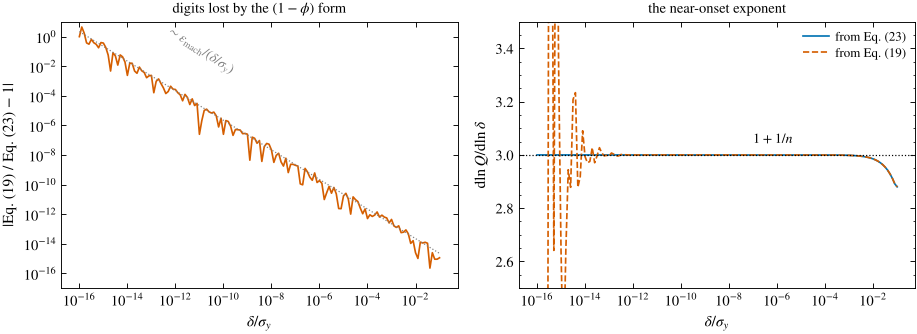

Fig. 9(a): the two exponent limits (3 and 2 for n = 0.5) agree with data/figure_data/fig09_transport_exponents.csv.


In [11]:
# The cancellation problem: Eq. (19) versus Eq. (23) as the onset is approached (n = 0.5, sigma_y = K = R = 1)
n = 0.5
eps = np.logspace(-16, -1, 151)                                      # delta / sigma_y
q19 = np.array([q19_from_delta(e, 1.0, 1.0, n) for e in eps])     # sigma_w = 1 + e is formed first, then 1 - phi
q23 = np.array([q23_from_delta(e, 1.0, 1.0, n) for e in eps])     # e enters directly
with np.errstate(divide="ignore", invalid="ignore"):
    rel = np.abs(q19 / q23 - 1)
    s19 = np.gradient(np.log(q19), np.log(eps))
    s23 = np.gradient(np.log(q23), np.log(eps))
print("delta/sigma_y   Eq.(19)/Eq.(23)-1")
for e in [1e-4, 1e-8, 1e-12, 1e-14, 1e-16]:
    i = np.argmin(np.abs(eps - e))
    print(f"  {eps[i]:.0e}      {q19[i] / q23[i] - 1:+.2e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.3))
ax1.loglog(eps, np.where(rel > 0, rel, np.nan), color=C["red"])
ax1.loglog(eps, 2.2e-16 / eps, color=C["grey"], ls=":", lw=0.8)
ax1.text(3e-13, 3e-3, r"$\sim\varepsilon_{\rm mach}/(\delta/\sigma_y)$", fontsize=9, color=C["grey"], rotation=-33)
ax1.set(xlabel=r"$\delta/\sigma_y$", ylabel="|Eq. (19) / Eq. (23) $-$ 1|", ylim=(1e-17, 10))
ax1.set_title("digits lost by the $(1-\\phi)$ form", fontsize=9.5)
ax2.semilogx(eps, s23, color=C["blue"], label="from Eq. (23)")
ax2.semilogx(eps, s19, color=C["red"], ls="--", label="from Eq. (19)")
ax2.axhline(1 + 1 / n, color="k", ls=":", lw=0.8)
ax2.text(1e-7, 3.03, r"$1+1/n$", fontsize=9, va="bottom")
ax2.set(xlabel=r"$\delta/\sigma_y$", ylabel=r"$\mathrm{d}\ln Q/\mathrm{d}\ln\delta$", ylim=(2.5, 3.5))
ax2.legend(fontsize=8.5, loc="upper right")
ax2.set_title("the near-onset exponent", fontsize=9.5)
fig.tight_layout()
plt.show()

# the exponent limits drawn in Fig. 9(a) are stored with the figure data
fd9 = pd.read_csv(ROOT / "data" / "figure_data" / "fig09_transport_exponents.csv", comment="#")
h = fd9[(fd9.panel == "(a)") & (fd9.kind == "hline")].set_index("series").y
assert np.isclose(h["near-yield limit 1+1/n"], 1 + 1 / n) and np.isclose(h["far-from-yield limit 1/n"], 1 / n)
print("Fig. 9(a): the two exponent limits (3 and 2 for n = 0.5) agree with data/figure_data/fig09_transport_exponents.csv.")

The relative error of Eq. (19) grows like $\varepsilon_{\rm mach}/(\delta/\sigma_y)$, exactly as expected for a difference of nearly equal numbers raised to a power of order one: only about four digits survive at $\delta/\sigma_y=10^{-12}$, and none at $10^{-16}$, where $1-\phi$ rounds to zero and $Q$ to $0$ (the slope becomes undefined). Eq. (23) returns the exponent $3$ down to $\delta/\sigma_y=10^{-16}$, the smallest value tested. The same cancellation is the reason why `scripts/hb_prediction.py` evaluates the flux with the dimensionless factors $z=\delta/\sigma_w$ and $\phi$ rather than with powers of large dimensional stresses.

### 4.6 The pipe energy identity, Eq. (S24) (row 11)

*Error exposed: invariant and dissipation errors.* For no-slip laminar pipe flow the pressure power per unit length equals the bulk dissipation,

$$
GQ=2\pi\int_0^R\left(\sigma_y\dot\gamma+K\dot\gamma^{\,n+1}\right)r\,\mathrm{d}r. \tag{S24}
$$

The plug contributes flux by translation but no dissipation. Note S11 A derives it by exchanging the order of integration; Note S9 E says that it "detects a missing factor of two in the invariant, a sign error or an inconsistent slip traction more reliably than a velocity plot". We evaluate the right-hand side through the tensor route, $\boldsymbol\tau\!:\!\mathsf D$ with $\mathsf D$ the shear tensor of the pipe, so that two mutants can be tried: the invariant without its factor of two (Sec. 3.1), and the dissipation *potential* $\sigma_y\dot\gamma+K\dot\gamma^{n+1}/(n+1)$ used in place of the dissipation *rate* (Note S1 C warns that "using $\Psi$ as viscous heating underestimates the rate-dependent contribution").

In [12]:
def dissipation_density(gd, ty, K, n, invariant_factor=2.0, potential=False):
    '''tau:D at a point of simple shear with rate gd, through the tensor law.'''
    if gd <= 0:
        return 0.0
    D = np.array([[0.0, gd / 2], [gd / 2, 0.0]])
    tau = hb_stress_tensor(D, ty, K, n, invariant_factor)
    if potential:                                   # mutant: K gd^(n+1)/(n+1) instead of K gd^(n+1)
        g = np.sqrt(invariant_factor * np.sum(D * D))
        return ty * g + K * g ** (n + 1) / (n + 1)
    return np.sum(tau * D)

def energy_ratio(tw, ty, K, n, R=1.0, **kw):
    '''G Q divided by the integrated dissipation; 1 if Eq. (S24) holds.'''
    G = 2 * tw / R
    rp = R * min(ty / tw, 1.0)
    diss = 2 * np.pi * quad(lambda r: dissipation_density(shear_rate(r, tw, ty, K, n, R), ty, K, n, **kw) * r, rp, R, epsabs=0, epsrel=1e-12, limit=200)[0]
    return G * pipe_q23(tw, ty, K, n, R) / diss

K, R = 0.8, 0.7
worst = max(abs(energy_ratio(2.0, phi * 2.0, K, n, R) - 1) for n in [0.35, 0.7, 1.0, 1.4] for phi in [0.0, 0.3, 0.9])
check("pressure work = dissipation, Eq. (S24), 12 cases", 1 + worst, 1.0, rtol=1e-8)
print("mutants:")
check("Eq. (S24) rejects the invariant without its factor 2", energy_ratio(2.0, 0.6, K, 0.7, R, invariant_factor=1.0), 1.0, rtol=1e-8, mutant=True)
check("Eq. (S24) rejects the potential used as dissipation", energy_ratio(2.0, 0.6, K, 0.7, R, potential=True), 1.0, rtol=1e-8, mutant=True)

  pass   : pressure work = dissipation, Eq. (S24), 12 cases           |rel. diff| = 5.1e-15
mutants:
  caught : Eq. (S24) rejects the invariant without its factor 2       0.819398 vs 1
  caught : Eq. (S24) rejects the potential used as dissipation        1.35492 vs 1


## 5. Other geometries

### 5.1 Plane channel, Eq. (20) (row 9)

*Error exposed: half-width and plug contributions.* With half-width $H$, $\sigma_w=GH$ and $q=2H^2n\,(\sigma_w/K)^{1/n}(1-\phi)^{1+1/n}\left[\dfrac{1-\phi}{2n+1}+\dfrac{\phi}{n+1}\right]$ per unit width, to be compared with $2\int_0^H u(y)\,\mathrm{d}y$ for the profile $u(y)=\dfrac{n}{n+1}\dfrac{H}{\sigma_w}K^{-1/n}\left[(\sigma_w-\sigma_y)^{1+1/n}-(\sigma_w|y|/H-\sigma_y)_+^{1+1/n}\right]$ (notebook 05, Sec. 6). The mutant integrates over one half of the channel only, the classic half-width slip; a mutant that stops the integral at the plug edge would fail in the same way.

In [13]:
def channel_u(y, tw, ty, K, n, H):
    return n / (n + 1) * H / tw * K ** (-1 / n) * ((tw - ty) ** ((n + 1) / n) - max(tw * abs(y) / H - ty, 0.0) ** ((n + 1) / n))

def channel_q20(tw, ty, K, n, H):
    p = ty / tw
    return 2 * H**2 * n * (tw / K) ** (1 / n) * (1 - p) ** ((n + 1) / n) * ((1 - p) / (2 * n + 1) + p / (n + 1))

tw, K, H = 2.0, 0.8, 0.6
worst = 0.0
for n in [0.4, 0.7, 1.0, 1.4]:
    for phi in [0.0, 0.2, 0.6, 0.9]:
        ty = phi * tw
        q_num = 2 * quad(lambda y: channel_u(y, tw, ty, K, n, H), 0, H, points=[phi * H], epsabs=0, epsrel=1e-12)[0]
        worst = max(worst, abs(channel_q20(tw, ty, K, n, H) / q_num - 1))
check("Eq. (20) = quadrature of the channel profile, 16 cases", 1 + worst, 1.0, rtol=1e-8)
check("Newtonian slot q = 2 G H^3/(3 mu)", channel_q20(2.0 * H, 0.0, 0.8, 1.0, H), 2 * 2.0 * H**3 / (3 * 0.8))
print("mutant (one half of the channel integrated):")
n, phi = 0.7, 0.6
check("Eq. (20) rejects the half-width mutant", quad(lambda y: channel_u(y, tw, phi * tw, K, n, H), 0, H, points=[phi * H])[0], channel_q20(tw, phi * tw, K, n, H), rtol=1e-8, mutant=True)

  pass   : Eq. (20) = quadrature of the channel profile, 16 cases     |rel. diff| = 6.2e-15
  pass   : Newtonian slot q = 2 G H^3/(3 mu)                          |rel. diff| = 2.2e-16
mutant (one half of the channel integrated):
  caught : Eq. (20) rejects the half-width mutant                     0.0523765 vs 0.104753


### 5.2 Thin layer, Eq. (28): Newtonian film and yielded film (rows 7 and 8)

*Errors exposed: yielded versus plug thickness; the plug-flux term and the exponents.* For a layer of depth $h$ with a no-slip base and a stress-free surface, $\sigma=G(h-z)$, only the basal layer $0<z<a=(h-\sigma_y/G)_+$ is sheared, and the depth-integrated flux is

$$
q=\left(\frac{G}{K}\right)^{1/n}\left[\frac{a^{2+1/n}}{2+1/n}+\frac{(h-a)\,a^{1+1/n}}{1+1/n}\right], \tag{28}
$$

whose second term is the flux carried by the pseudo-plug $a<z<h$ moving at the speed $u(a)$. For $\sigma_y=0$, $n=1$ it gives $Gh^3/(3\mu)$. The independent reference is a double quadrature: $u(z)=\int_0^{\min(z,a)}\dot\gamma\,\mathrm{d}z'$, then $q=\int_0^a u\,\mathrm{d}z+(h-a)u(a)$.

Two mutants: (i) the yielded thickness confused with the plug thickness, $a=\sigma_y/G$, which the **Newtonian** limit catches because it then gives $q=0$ for a film with no yield stress; (ii) the plug-flux term omitted, which the Newtonian limit cannot catch (there $h-a=0$) but the yielded-film quadrature does.

In [14]:
def thin_q28(G, h, ty, K, n, plug_term=True, confuse_thickness=False):
    a = ty / G if confuse_thickness else max(h - ty / G, 0.0)
    return (G / K) ** (1 / n) * (a ** (2 + 1 / n) / (2 + 1 / n) + (plug_term * (h - a)) * a ** (1 + 1 / n) / (1 + 1 / n))

def thin_q_double_quad(G, h, ty, K, n):
    a = max(h - ty / G, 0.0)
    rate = lambda z: ((G * (h - z) - ty) / K) ** (1 / n) if z < a else 0.0
    u = lambda z: quad(rate, 0, min(z, a), epsabs=1e-13)[0]
    return quad(u, 0, a, epsabs=1e-13)[0] + (h - a) * u(a)

G, h, mu = 3.0, 0.3, 2.0
print("correct implementation:")
check("Newtonian film: Eq. (28) = G h^3/(3 mu)", thin_q28(G, h, 0.0, mu, 1.0), G * h**3 / (3 * mu))
worst = 0.0
for n in [0.4, 0.7, 1.0, 1.3]:
    for ty in [0.0, 0.2, 0.6]:
        G, h, K = 2.0, 0.5, 0.9
        worst = max(worst, abs(thin_q28(G, h, ty, K, n) / thin_q_double_quad(G, h, ty, K, n) - 1))
check("yielded film: Eq. (28) = double quadrature, 12 cases", 1 + worst, 1.0, rtol=1e-7)
print("mutants:")
check("Newtonian film rejects a = sigma_y/G (plug thickness)", thin_q28(3.0, 0.3, 0.0, mu, 1.0, confuse_thickness=True), 3.0 * 0.3**3 / (3 * mu), mutant=True)
print(f"  Newtonian film is blind to the missing plug term: {thin_q28(3.0, 0.3, 0.0, mu, 1.0, plug_term=False) / (3.0 * 0.3**3 / (3 * mu)):.6f} x exact")
check("yielded film rejects the missing plug term", thin_q28(2.0, 0.5, 0.6, 0.9, 0.7, plug_term=False), thin_q_double_quad(2.0, 0.5, 0.6, 0.9, 0.7), rtol=1e-7, mutant=True)

correct implementation:
  pass   : Newtonian film: Eq. (28) = G h^3/(3 mu)                    |rel. diff| = 0.0e+00
  pass   : yielded film: Eq. (28) = double quadrature, 12 cases       |rel. diff| = 8.8e-12
mutants:
  caught : Newtonian film rejects a = sigma_y/G (plug thickness)      0 vs 0.0135
  Newtonian film is blind to the missing plug term: 1.000000 x exact
  caught : yielded film rejects the missing plug term                 0.00366293 vs 0.0114197


### 5.3 Concentric cylinders, Eq. (21): Newtonian, power-law and Bingham, fully and partly yielded (row 10)

*Error exposed: yield-radius limit and torque scaling.* With a stationary outer cylinder and torque per unit length $T$, $\sigma(r)=T/(2\pi r^2)$ and

$$
\Omega=\int_{R_i}^{\min(r_y,R_o)}\frac1r\left(\frac{\sigma(r)-\sigma_y}{K}\right)^{1/n}\mathrm{d}r,\qquad r_y=\sqrt{\frac{T}{2\pi\sigma_y}}. \tag{21}
$$

Closed forms (notebook 04, Sec. 5.1): Newtonian $\Omega=\dfrac{T}{4\pi\mu}\left(\dfrac1{R_i^2}-\dfrac1{R_o^2}\right)$; power law $\Omega=\dfrac n2\left(\dfrac{T}{2\pi K}\right)^{1/n}\left(R_i^{-2/n}-R_o^{-2/n}\right)$; Bingham with $r_m=\min(r_y,R_o)$: $\Omega=\dfrac{T}{4\pi\mu_p}\left(\dfrac1{R_i^2}-\dfrac1{r_m^2}\right)-\dfrac{\sigma_y}{\mu_p}\ln\dfrac{r_m}{R_i}$, which covers both the fully ($r_y\ge R_o$) and the partly ($r_y<R_o$) yielded gap. Mutants: the stress written as $T/(2\pi r)$ (wrong torque scaling), and the upper limit $r_y$ not capped at $R_o$ (integrating through the outer wall when the gap is fully yielded).

In [15]:
def couette_omega(T, ty, K, n, Ri, Ro, torque_power=2, cap_at_Ro=True):
    if T <= 2 * np.pi * Ri**2 * ty:
        return 0.0
    ry = np.sqrt(T / (2 * np.pi * ty)) if ty > 0 else np.inf
    top = min(ry, Ro) if cap_at_Ro else ry
    sigma = lambda r: T / (2 * np.pi * r**torque_power)
    return quad(lambda r: ((sigma(r) - ty) / K) ** (1 / n) / r, Ri, top, epsabs=0, epsrel=1e-12)[0]

Ri, Ro, mu = 1.0, 1.4, 2.0
print("correct implementation:")
for T in [10.0, 30.0]:
    check(f"Couette Newtonian, T={T}", couette_omega(T, 0.0, mu, 1.0, Ri, Ro), T / (4 * np.pi * mu) * (1 / Ri**2 - 1 / Ro**2), rtol=1e-10)
    for n in [0.5, 0.8]:
        check(f"Couette power law, T={T}, n={n}", couette_omega(T, 0.0, 0.7, n, Ri, Ro), n / 2 * (T / (2 * np.pi * 0.7)) ** (1 / n) * (Ri ** (-2 / n) - Ro ** (-2 / n)), rtol=1e-8)
    for ty in [0.5, 2.0, 4.0]:
        if T <= 2 * np.pi * Ri**2 * ty:
            continue
        rm = min(np.sqrt(T / (2 * np.pi * ty)), Ro)
        state = "partly" if rm < Ro else "fully"
        check(f"Couette Bingham, T={T}, sigma_y={ty} ({state} yielded)", couette_omega(T, ty, mu, 1.0, Ri, Ro), T / (4 * np.pi * mu) * (1 / Ri**2 - 1 / rm**2) - ty / mu * np.log(rm / Ri), rtol=1e-8)
print("mutants:")
check("Couette rejects sigma = T/(2 pi r)", couette_omega(10.0, 0.0, mu, 1.0, Ri, Ro, torque_power=1), 10.0 / (4 * np.pi * mu) * (1 / Ri**2 - 1 / Ro**2), rtol=1e-8, mutant=True)
check("Couette rejects r_y not capped at R_o (fully yielded Bingham)", couette_omega(30.0, 0.5, mu, 1.0, Ri, Ro, cap_at_Ro=False), 30.0 / (4 * np.pi * mu) * (1 / Ri**2 - 1 / Ro**2) - 0.5 / mu * np.log(Ro / Ri), rtol=1e-8, mutant=True)

correct implementation:
  pass   : Couette Newtonian, T=10.0                                  |rel. diff| = 2.2e-16
  pass   : Couette power law, T=10.0, n=0.5                           |rel. diff| = 1.1e-16
  pass   : Couette power law, T=10.0, n=0.8                           |rel. diff| = 3.3e-16
  pass   : Couette Bingham, T=10.0, sigma_y=0.5 (fully yielded)       |rel. diff| = 2.2e-16
  pass   : Couette Newtonian, T=30.0                                  |rel. diff| = 2.2e-16
  pass   : Couette power law, T=30.0, n=0.5                           |rel. diff| = 2.2e-16
  pass   : Couette power law, T=30.0, n=0.8                           |rel. diff| = 0.0e+00
  pass   : Couette Bingham, T=30.0, sigma_y=0.5 (fully yielded)       |rel. diff| = 0.0e+00
  pass   : Couette Bingham, T=30.0, sigma_y=2.0 (fully yielded)       |rel. diff| = 0.0e+00
  pass   : Couette Bingham, T=30.0, sigma_y=4.0 (partly yielded)      |rel. diff| = 1.0e-14
mutants:
  caught : Couette rejects sigma = T/(2 pi r)  

## 6. Dimensionless numbers and conventions

### 6.1 Newtonian Metzner–Reed Reynolds number (row 6), and Fanning versus Darcy

*Error exposed: diameter and factor-of-eight errors.* Eq. (9), $\mathrm{Re_{MR}}=\rho U^{2-n'}D^{n'}/(K'8^{n'-1})$, must reduce to $\rho UD/\mu$ for $n'=1$, $K'=\mu$. Two mutants: the radius used for $D$, and $8^{n'}$ written for $8^{n'-1}$ (invisible in the power-law *form* of the formula but a factor of 8 in the Newtonian limit). We add the convention check of Note S9 E: $\Delta p=4\sigma_wL/D=2f_F\rho U^2L/D$ with $f_F=16/\mathrm{Re_{MR}}$ in laminar flow; the mutant inserts the Fanning factor into the Darcy formula $\Delta p=f_D\rho U^2L/(2D)$ and is low by a factor of four. (Notebook 08 treats $n'$, $K'$ and the turbulent branch.)

In [16]:
def re_mr(rho, U, D, npr, Kpr, eight_power_offset=-1, length=None):
    L = D if length is None else length
    return rho * U ** (2 - npr) * L**npr / (Kpr * 8 ** (npr + eight_power_offset))

rho, U, D, mu = 1200.0, 1.3, 0.1, 0.5
print("correct implementation:")
check("Newtonian Re_MR = rho U D/mu", re_mr(rho, U, D, 1.0, mu), rho * U * D / mu)
Q, L, ty, K, n = 0.01, 500.0, 5.0, 0.5, 0.7                      # Example 1 of Note S15 (notebooks 02, 08, 18)
tw = brentq(lambda s: pipe_q23(s, ty, K, n, D / 2) - Q, ty + 1e-10, 1000.0, xtol=1e-13)
U = Q / (np.pi * (D / 2) ** 2)
Re = 8 * rho * U**2 / tw                                          # Eq. (9) for any laminar flow curve
check("Fanning identity: 4 sigma_w L/D = (16/Re_MR) 2 rho U^2 L/D", 4 * tw * L / D, (16 / Re) * 2 * rho * U**2 * L / D)
print("mutants:")
check("Re_MR rejects the radius used for D", re_mr(rho, 1.3, D, 1.0, mu, length=D / 2), rho * 1.3 * D / mu, mutant=True)
check("Re_MR rejects 8^n' in place of 8^(n'-1)", re_mr(rho, 1.3, D, 1.0, mu, eight_power_offset=0), rho * 1.3 * D / mu, mutant=True)
check("Fanning factor used in the Darcy formula (factor 4)", (16 / Re) * rho * U**2 * L / (2 * D), 4 * tw * L / D, mutant=True)

correct implementation:
  pass   : Newtonian Re_MR = rho U D/mu                               |rel. diff| = 0.0e+00
  pass   : Fanning identity: 4 sigma_w L/D = (16/Re_MR) 2 rho U^2 L/D |rel. diff| = 0.0e+00
mutants:
  caught : Re_MR rejects the radius used for D                        156 vs 312
  caught : Re_MR rejects 8^n' in place of 8^(n'-1)                    39 vs 312
  caught : Fanning factor used in the Darcy formula (factor 4)        100243 vs 400970


### 6.2 Spreading coefficient $C=225/(128\pi^2)$ (row 14)

*Error exposed: profile and volume prefactor.* In the shallow spreading regime the arrested layer has the square-root profile $h^2=2\sigma_y(R-r)/(\rho g)$ (Roussel and Coussot, 2005), and integrating the volume $V=\int_0^R2\pi r\,h\,\mathrm{d}r$ gives Eq. (S26), $\sigma_y=C\rho gV^2R^{-5}$ with $C=225/(128\pi^2)$ — the formula of Example 2 of Note S15 (notebook 18). The test recovers $\sigma_y$ from the quadrature of the profile; the mutant replaces the volume integral by a cylinder of the maximum height, $V=\pi R^2h(0)$.

In [17]:
rho_c, g, R_c, ty_c = 2300.0, 9.81, 0.35, 20.0
h_profile = lambda r: np.sqrt(2 * ty_c * (R_c - r) / (rho_c * g))
V = quad(lambda r: 2 * np.pi * r * h_profile(r), 0, R_c, epsabs=1e-14)[0]
C_spread = 225 / (128 * np.pi**2)
print("correct implementation:")
check("spreading: sigma_y = C rho g V^2/R^5 with C = 225/(128 pi^2)", C_spread * rho_c * g * V**2 / R_c**5, ty_c, rtol=1e-8)
print("mutant (volume taken as pi R^2 h_max):")
V_bad = np.pi * R_c**2 * h_profile(0.0)
check("spreading rejects the cylinder volume", C_spread * rho_c * g * V_bad**2 / R_c**5, ty_c, rtol=1e-8, mutant=True)

correct implementation:
  pass   : spreading: sigma_y = C rho g V^2/R^5 with C = 225/(128 pi^2) |rel. diff| = 0.0e+00
mutant (volume taken as pi R^2 h_max):
  caught : spreading rejects the cylinder volume                      70.3125 vs 20


### 6.3 Sphere convention $Y_g=3Y_R/2$ (row 15)

*Error exposed: force versus radius yield number.* The gravity yield number of Table IV, $Y_g=3\sigma_y/(2\Delta\rho gR)$, compares the yield force $\sim\sigma_yR^2$ with the net weight $\frac43\pi R^3\Delta\rho g$; the radius-based number $Y_R=\sigma_y/(\Delta\rho gR)$ omits the $3/2$. The arrest threshold $Y_g\approx0.143$ (Beris et al., 1985) is therefore $Y_R\approx0.0953$ (Example 3 of Note S15; notebook 02). The mutant applies the 0.143 threshold to $Y_R$ and overestimates the yield stress needed to hold a cutting by 50 %.

In [18]:
ty_s, drho, R_s, g = 3.5, 1500.0, 0.0025, 9.81
print("correct implementation:")
check("Y_g = 3 Y_R / 2", 3 * ty_s / (2 * drho * g * R_s), 1.5 * ty_s / (drho * g * R_s))
check("Example 3: sigma_y at Y_g = 0.143 (3.51 Pa)", 0.143 * 2 * drho * g * R_s / 3, 3.5070750)
print("mutant (0.143 applied to Y_R):")
check("sphere rejects the threshold applied to Y_R", 0.143 * drho * g * R_s, 0.143 * 2 * drho * g * R_s / 3, mutant=True)

correct implementation:
  pass   : Y_g = 3 Y_R / 2                                            |rel. diff| = 0.0e+00
  pass   : Example 3: sigma_y at Y_g = 0.143 (3.51 Pa)                |rel. diff| = 0.0e+00
mutant (0.143 applied to Y_R):
  caught : sphere rejects the threshold applied to Y_R                5.26061 vs 3.50707


## 7. The regularized law: plug-radius diagnostic, Eq. (30), and Fig. 12(b) (row 16)

*Error exposed: inversion of the regularized law.* In pipe flow with the HB–Papanastasiou law $\sigma=\sigma_y(1-e^{-m\dot\gamma})+K\dot\gamma^n$, the boundary of the set $\dot\gamma<\varepsilon$ is given exactly by Eq. (30),

$$
\frac{r_\varepsilon}{R}=\min\left\{1,\ \frac{\sigma_y(1-e^{-m\varepsilon})+K\varepsilon^n}{\sigma_w}\right\},
$$

because the pipe stress $\sigma_wr/R$ is fixed by momentum balance and the regularized law is monotone. The test inverts the law numerically: at the stress $\sigma_wr_\varepsilon/R$ the root of $\sigma(\dot\gamma)=\sigma_wr_\varepsilon/R$ must be $\varepsilon$. The mutant uses the ideal-HB radius $\phi+K\varepsilon^n/\sigma_w$ — the $m\to\infty$ limit, which Sec. VII G says is reached only when $m\varepsilon\to\infty$ — and is wrong at finite $m\varepsilon$. (Notebook 07 discusses the noncommuting limits; `np.expm1` is used so that $1-e^{-m\varepsilon}$ is accurate for small $m\varepsilon$ — another cancellation.)

In [19]:
ty, K, n, tw = 1.0, 1.0, 0.5, 2.0
hbp_stress = lambda g, m: ty * (-np.expm1(-m * g)) + K * g**n
print("correct implementation:")
for m in [10, 1000]:
    eps = 0.003
    r_eps = (ty * (-np.expm1(-m * eps)) + K * eps**n) / tw                         # Eq. (30)
    recovered = brentq(lambda g: hbp_stress(g, m) - tw * r_eps, 0.0, 1.0, xtol=1e-14)
    check(f"Eq. (30) inverts the HB-Papanastasiou law, m={m}", recovered, eps, rtol=1e-9)
print("mutant (ideal-HB radius phi + K eps^n/sigma_w at m = 10):")
m, eps = 10, 0.003
r_bad = (ty + K * eps**n) / tw
check("Eq. (30) rejects the m -> infinity radius at finite m eps", brentq(lambda g: hbp_stress(g, m) - tw * r_bad, 0.0, 1.0, xtol=1e-14), eps, rtol=1e-9, mutant=True)

correct implementation:
  pass   : Eq. (30) inverts the HB-Papanastasiou law, m=10            |rel. diff| = 1.1e-16
  pass   : Eq. (30) inverts the HB-Papanastasiou law, m=1000          |rel. diff| = 4.4e-16
mutant (ideal-HB radius phi + K eps^n/sigma_w at m = 10):
  caught : Eq. (30) rejects the m -> infinity radius at finite m eps  0.122164 vs 0.003


We now reproduce Fig. 12(b) of the review — the apparent plug radius from Eq. (30) against $M=m\dot\gamma_y$ for three rate thresholds, at $\phi=0.5$ and $n=0.5$ with $\sigma_y=K=R=1$ (so that $\dot\gamma_y=1$ and $M=m$) — and check every plotted value against `data/figure_data/fig12_hbp_pipe.csv`.

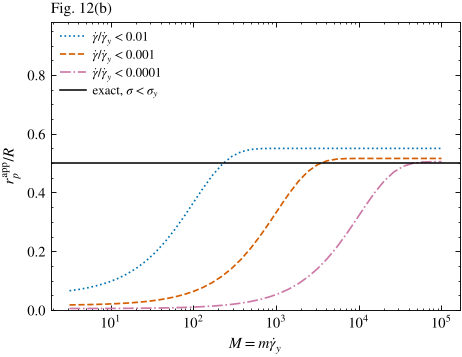

Fig. 12(b): the three Eq. (30) curves and the exact plug radius agree with data/figure_data/fig12_hbp_pipe.csv (rtol 1e-8).


In [20]:
fd12 = pd.read_csv(ROOT / "data" / "figure_data" / "fig12_hbp_pipe.csv", comment="#")
ty, K, n, phi = 1.0, 1.0, 0.5, 0.5
tw = ty / phi
m_grid = np.logspace(0.5, 5, 40)
fig, ax = plt.subplots(figsize=(4.8, 3.4))
for eps, col, ls in [(1e-2, C["blue"], ":"), (1e-3, C["red"], "--"), (1e-4, C["purple"], "-.")]:
    rp = np.minimum(1.0, (ty * (-np.expm1(-m_grid * eps)) + K * eps**n) / tw)      # Eq. (30)
    ax.semilogx(m_grid, rp, color=col, ls=ls, label=rf"$\dot\gamma/\dot\gamma_y<{eps:g}$")
    s = fd12[(fd12.panel == "(b)") & (fd12.series == rf"$\dot\gamma/\dot\gamma_y<{eps:g}$")].sort_values("index")
    assert len(s) == 40 and np.allclose(s.x, m_grid, rtol=1e-8) and np.allclose(s.y, rp, rtol=1e-8), eps
ax.axhline(phi, color="k", lw=1.0, label=r"exact, $\sigma<\sigma_y$")
hl = fd12[(fd12.panel == "(b)") & (fd12.kind == "hline")].iloc[0]
assert np.isclose(hl.y, phi)
ax.set(xlabel=r"$M=m\dot\gamma_y$", ylabel=r"$r_p^{\rm app}/R$", ylim=(0, 0.98))
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Fig. 12(b)", loc="left", fontsize=10)
plt.show()
print("Fig. 12(b): the three Eq. (30) curves and the exact plug radius agree with data/figure_data/fig12_hbp_pipe.csv (rtol 1e-8).")

At small $M$ the rate-defined "plug" is far smaller than the ideal one — at $M=10$ and $\varepsilon=10^{-2}$ the apparent radius is only $r/R\approx0.1$, because the weakly regularized material creeps faster than $\varepsilon\dot\gamma_y$ almost everywhere inside the true plug — and at large $M$ the apparent radius converges to $\phi+K\varepsilon^n/\sigma_w$ ($0.55$ for $\varepsilon=10^{-2}$), slightly above $\phi$ for finite $\varepsilon$. Both limits are reproduced by Eq. (30), and the rule used to define a plotted plug must be stated (Sec. VII G).

## 8. The review's own suite

The sixteen identities above are those of `scripts/verify_equations.py` (which also runs a few further checks). We run it here — it takes well under a second — and compare its worked examples with the values printed in Supplementary Note S15 B.

In [21]:
from verify_equations import run as run_review_suite
record = run_review_suite()
print("status:", record["status"], "-", len(record["checks"]), "groups of checks:")
for item in record["checks"]:
    print("   ", item)
ex = record["worked_examples"]
printed = [("Example 1, pressure drop (kPa)", ex["pipe"]["pressure_drop_kPa"], 401, 0),
           ("Example 1, Re_MR", ex["pipe"]["Re_MR"], 776, 0),
           ("Example 2, sigma_y at R = 350 mm (Pa)", ex["spread"]["yield_stress_R035_Pa"], 23, 0),
           ("Example 2, sigma_y at R = 300 mm (Pa)", ex["spread"]["yield_stress_R030_Pa"], 50, 0),
           ("Example 3, sigma_y holding the cutting (Pa)", ex["sphere"]["yield_stress_Pa"], 3.51, 2)]
for name, value, value_printed, digits in printed:
    assert round(value, digits) == value_printed, name
    print(f"  {name:45s} {value:9.3f}   printed in Note S15 B: {value_printed}")
print("the worked examples of scripts/verify_equations.py reproduce the printed values of Note S15 B.")
print(f"\nThis notebook: {len(PASSED)} identities verified, {len(CAUGHT)} deliberately wrong implementations rejected.")

status: PASS - 20 groups of checks:
    25 pipe-formula equivalence cases
    25 direct pipe quadratures
    25 pressure-work/dissipation balances
    Newtonian Poiseuille limit
    Bingham Buckingham-Reiner limit
    Near-onset exponents
    Partly yielded Couette near-onset asymptotics
    Ideal spherical cavern torque prefactor
    Newtonian Metzner-Reed limit
    Newtonian film limit of Eq. thin_flux
    12 thin-layer flux quadratures with yield (Eq. thin_flux)
    16 plane-channel flux quadratures (Sec. VII A)
    Full Couette relation: Newtonian, power-law and Bingham (full and partial yielding)
    Uniaxial and planar extension stresses with yield (Eqs. uniaxial_hb, planar_hb) and Newtonian limit
    Normal-stress invariant identity (Eq. normal_invariant)
    Spreading coefficient C=225/(128 pi^2) by volume quadrature
    Sphere yield-number conventions Y_g=3Y_R/2
    Rate-threshold inversion m=10
    Rate-threshold inversion m=1000
    Fanning pressure-loss identity and worked 

## 9. Separating the error sources (Sec. VII I, Table IX; Note S18 B, step 3) — beyond the article

The identities above test *formulas*. A code that discretizes the problem adds three further error sources that Table IX asks to be separated: **space** (mesh), **time** (step) and the **algebraic solve** (residual tolerance). The following one-dimensional experiment, made for this notebook, shows how to separate the first and the third, and why near arrest an absolute tolerance is needed.

The task is the design calculation of notebook 05: find the wall stress $\sigma_w$ that delivers a prescribed flow rate $Q_0$. We take $Q_0$ from the exact Eq. (23) at $\sigma_w=2\sigma_y$ ($n=0.5$, $\sigma_y=K=R=1$), so the exact answer is known, and solve it with a deliberately "numerical" model:

* *Space*: the flow rate of a trial $\sigma_w$ is computed as $Q_N(\sigma_w)=2\pi\int_0^Ru\,r\,\mathrm{d}r$ by the trapezoidal rule on $N$ equally spaced radii, with $u$ from Eq. (18). The profile has a kink at $r_p$, so the discretization error decreases at best as $N^{-2}$.
* *Algebraic solve*: the equation $Q_N(\sigma_w)=Q_0$ is solved with Brent's method at a tolerance `xtol` on $\sigma_w$.

Both errors are then measured in the same quantity, the computed $\sigma_w$, for every combination of $N$ and `xtol`.

A convergence study that refines $N$ while `xtol` dominates learns nothing — "tighten algebraic tolerances until they no longer dominate the mesh change, then refine mesh and regularization together" (Sec. VII I).

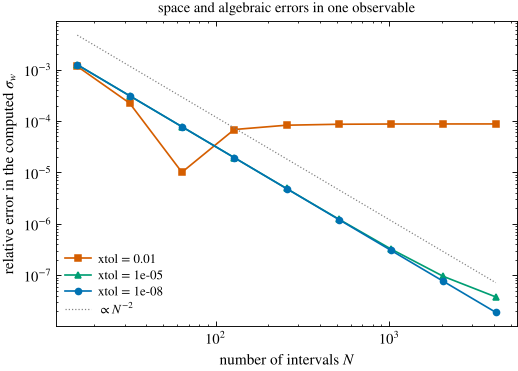

relative error in sigma_w:
     N   xtol=0.01     xtol=1e-05    xtol=1e-08    
     16   1.2e-03       1.2e-03       1.2e-03       
     32   2.2e-04       3.1e-04       3.1e-04       
     64   1.0e-05       7.8e-05       7.8e-05       
    128   6.8e-05       1.9e-05       1.9e-05       
    256   8.3e-05       4.9e-06       4.8e-06       
    512   8.6e-05       1.2e-06       1.2e-06       
   1024   8.7e-05       3.2e-07       3.0e-07       
   2048   8.8e-05       9.5e-08       7.6e-08       
   4096   8.8e-05       3.8e-08       1.9e-08       


In [22]:
def velocity(r, tw, ty, K, n, R=1.0):
    '''Eq. (18); constant (plug velocity) for r <= r_p.'''
    excess = np.clip(tw * np.abs(np.asarray(r, float)) / R - ty, 0.0, None)
    return n / (n + 1) * (R / tw) * K ** (-1 / n) * ((tw - ty) ** ((n + 1) / n) - excess ** ((n + 1) / n))

def Q_trap(s, N, ty, K, n, R=1.0):
    '''Flow rate at wall stress s from the trapezoidal rule on N intervals (the "discretized model").'''
    r = np.linspace(0, R, N + 1)
    return 2 * np.pi * np.trapezoid(velocity(r, s, ty, K, n, R) * r, r)

ty, K, n, R, tw = 1.0, 1.0, 0.5, 1.0, 2.0
Q0 = pipe_q23(tw, ty, K, n, R)                       # prescribed flow rate; the exact answer is sigma_w = 2
Ns = np.array([16, 32, 64, 128, 256, 512, 1024, 2048, 4096])
xtols = [1e-2, 1e-5, 1e-8]
err = {x: np.array([abs(brentq(lambda s: Q_trap(s, N, ty, K, n, R) - Q0, ty, 10 * tw, xtol=x, rtol=4 * np.finfo(float).eps) / tw - 1)
                    for N in Ns]) for x in xtols}

fig, ax = plt.subplots(figsize=(5.4, 3.6))
for x, col, mk in zip(xtols, [C["red"], C["green"], C["blue"]], ["s", "^", "o"]):
    ax.loglog(Ns, err[x], mk + "-", ms=4, color=col, label=f"xtol = {x:g}")
ax.loglog(Ns, 1.2 / Ns**2, color=C["grey"], ls=":", lw=0.8, label=r"$\propto N^{-2}$")
ax.set(xlabel="number of intervals $N$", ylabel=r"relative error in the computed $\sigma_w$")
ax.legend(fontsize=8.5, loc="lower left")
ax.set_title("space and algebraic errors in one observable", fontsize=9.5)
plt.show()
print("relative error in sigma_w:")
print("     N   " + "".join(f"xtol={x:<9g}" for x in xtols))
for i, N in enumerate(Ns):
    print(f"  {N:5d}   " + "".join(f"{err[x][i]:<14.1e}" for x in xtols))

With the loose tolerance, `xtol` $=10^{-2}$, the error in $\sigma_w$ stalls near $9\times10^{-5}$ from $N\approx256$ on: refining the mesh beyond that changes nothing, because the algebraic error dominates (at $N=64$ the two errors happen to partly cancel, which a single run would mistake for convergence). With `xtol` $=10^{-5}$ or $10^{-8}$ the error falls as $N^{-2}$, from $8\times10^{-5}$ at $N=64$ to about $2\times10^{-8}$ at $N=4096$ for the tightest tolerance — only then does a mesh study measure the mesh.

**Near arrest, use an absolute flux tolerance.** The relative sensitivity of $Q$ to the wall stress is $\mathrm{d}\ln Q/\mathrm{d}\ln\sigma_w=(1+1/n)\sigma_w/\delta$ near onset (Sec. 4.5), so a tiny absolute error in $\sigma_w$ — a residual, a round-off — becomes a huge *relative* error in $Q$ while the absolute error in $Q$ stays tiny. That is why Sec. VII I asks for "an absolute flux tolerance and a bracketed pressure threshold" rather than a relative error near arrest.

In [23]:
d_sigma = 1e-9 * tw                       # an absolute perturbation of the wall stress (e.g. a residual)
print("delta/sigma_y    |dQ|/Q (relative)   |dQ| (absolute, units of pi R^3 (sigma_y/K)^(1/n))")
for e in [1e-1, 1e-3, 1e-5, 1e-7]:
    q0 = pipe_q23(ty * (1 + e), ty, K, n, R)
    dq = pipe_q23(ty * (1 + e) + d_sigma, ty, K, n, R) - q0
    print(f"  {e:.0e}          {dq / q0:10.2e}         {dq / np.pi:10.2e}")
print("the relative error explodes as 1/delta; the absolute error shrinks: report the latter near arrest.")

delta/sigma_y    |dQ|/Q (relative)   |dQ| (absolute, units of pi R^3 (sigma_y/K)^(1/n))
  1e-01            5.73e-08           1.66e-11
  1e-03            6.00e-06           2.00e-15
  1e-05            6.00e-04           2.00e-19
  1e-07            6.12e-02           2.04e-23
the relative error explodes as 1/delta; the absolute error shrinks: report the latter near arrest.


## 10. From one dimension to a solver: Tables VIII and IX, Note S18 B

The checks of this notebook are Step 1 (material point) and Step 2 (canonical boundary-value problem) of the verification sequence of Note S18 B. For a multidimensional code the review's Table VIII lists what to compare next, in increasing difficulty:

| Problem | Reference | Quantities to compare | Principal test |
|---|---|---|---|
| Pipe/channel flow | Eqs. (19) and (20) | flow rate, profile, plug radius | scaling and constitutive law |
| Couette rheometry | Eq. (21) | torque–speed, yielded fraction | curved geometry and inversion |
| Square duct | Saramito and Roquet (2001) | flow rate, stagnant corner zones | two-dimensional plug topology |
| Lid-driven cavity | Syrakos, Georgiou and Alexandrou (2013) | vortex center, yielded regions | recirculating flow |
| Cylinder between plates | Zisis and Mitsoulis (2002); Roquet and Saramito (2003) | drag and yield topology | unstructured discretization |
| Settling sphere | Beris et al. (1985); Liu, Muller and Denn (2002) | drag, arrest, yield surface | three-dimensional stress, critical yield number |
| Expansion and contraction | Alexandrou, McGilvreay and Burgos (2001) | pressure loss, stagnant zones | corners and plug detection |
| Squeeze flow | O'Donovan and Tanner (1984) | force–gap curve | lubrication pseudo-plug |
| Dam break/slump | Roussel and Coussot (2005) | front and final shape | free surface and arrest |

Its caption carries the practical rule: *integral quantities from independent methods usually agree before yield-surface shapes do.* Test the flow rate, the drag and the pressure loss first; compare plug shapes last, and only with the classification rule stated (Sec. VII G, Note S10). Steps 3–5 of Note S18 B then separate the convergence dimensions (Sec. 9 above), audit the additional physics (mass and curvature for free surfaces, boundary power for slip, stress transport for elasticity) and, only then, validate against an experiment not used in calibration — stating whether a result is code verification, material validation or an illustrative calculation. Table SVII (Note S18 C) lists the digital record that makes such a comparison repeatable: raw observations with units, instrument model, fit record with reference rate and seed, prediction record with mesh and regularization, and the verification record itself — "tests, reference values, residual definitions and convergence results". This notebook is an example of that last item.

## 11. Try it yourself

**Exercise 1 — the signed form, Eq. (S1).** Note S1 A gives the inverse law for a signed stress, $a=\mathrm{sgn}(\sigma_{21})\,[(|\sigma_{21}|-\sigma_y)_+/K]^{1/n}$. Write it as a function, test that it is odd in $\sigma_{21}$ and zero inside $[-\sigma_y,\sigma_y]$, and build a mutant that raises a negative rate to the power $n$ (as a careless finite-volume update would) — what does it return?

*Hint:* `np.sign` and `np.clip`; the mutant is `K * a**n` with `a < 0` and non-integer `n`.

<details><summary>Solution</summary>

```python
def inverse_signed(s21, ty, K, n):
    return np.sign(s21) * (np.clip(np.abs(s21) - ty, 0, None) / K) ** (1 / n)
s = np.linspace(-3, 3, 13)
a = inverse_signed(s, 1.0, 1.0, 0.5)
assert np.allclose(a, -inverse_signed(-s, 1.0, 1.0, 0.5)) and np.all(a[np.abs(s) <= 1.0] == 0)
print(1.0 * (-0.5) ** 0.5)   # the mutant: a complex number (nan in float arrays) - not a stress
```
The correct law is odd and vanishes on the rigid branch; the mutant produces `nan` (or a complex number), which is why Note S1 A says that raising a negative rate to a non-integer power "is not a valid real-valued law".
</details>

**Exercise 2 — the energy identity with slip.** Note S9 E adds $2\pi R\sigma_wu_s$ to the right-hand side of Eq. (S24) when the wall slips with velocity $u_s$. With the Navier-type law of notebook 06 (slip velocity proportional to the wall stress above a slip threshold, or simply a prescribed $u_s$), the flow rate is the no-slip value plus $\pi R^2u_s$. Verify the extended identity, and show that forgetting the boundary term makes the balance fail by exactly the slip power.

*Hint:* $Q_{\rm slip}=Q_{\rm no\,slip}+\pi R^2u_s$ and $G=2\sigma_w/R$, so the extra pressure power is $G\pi R^2u_s=2\pi R\sigma_wu_s$.

<details><summary>Solution</summary>

```python
tw, ty, K, n, R, us = 2.0, 0.6, 0.8, 0.7, 0.7, 0.05
G = 2 * tw / R
Q_ns = pipe_q23(tw, ty, K, n, R)
diss = 2 * np.pi * quad(lambda r: dissipation_density(shear_rate(r, tw, ty, K, n, R), ty, K, n) * r,
                      ty / tw * R, R, epsabs=0, epsrel=1e-12)[0]   # bulk dissipation by quadrature
lhs = G * (Q_ns + np.pi * R**2 * us)
print(lhs / (diss + 2 * np.pi * R * tw * us) - 1)  # 0 to round-off
print(lhs / diss - 1)                              # the mutant: the balance fails by the slip power fraction
```
The extended identity holds to round-off; without the boundary term the pressure power exceeds the bulk dissipation by $2\pi R\sigma_wu_s/(GQ_{\rm no\,slip})$, about 17 % here — "an omitted energy flux can masquerade as a constitutive error" (Note S1 C).
</details>

**Exercise 3 — a Couette near-onset exponent.** `scripts/verify_equations.py` also checks the near-onset asymptote of the partly yielded Couette cell (Note S7 A, Eq. (S16)): for a bob stress $\sigma_b=\sigma_y+\delta$ with $\delta\ll\sigma_y$, $\Omega\sim\dfrac{n\,\delta^{1+1/n}}{2(n+1)K^{1/n}\sigma_y}$. Using `couette_omega` from Sec. 5.3 with $T=2\pi R_i^2\sigma_b$, verify the asymptote at $\delta/\sigma_y=10^{-5}$ for $n=0.4,0.7,1$, and compute the logarithmic slope of $\Omega$ against $\delta$. Is it the same exponent as in the pipe?

*Hint:* the slope should come out as $1+1/n$ (Table SIV: the pipe, the channel and the Couette cell share the near-onset exponent because in each a thin sheared layer opens next to the wall).

<details><summary>Solution</summary>

```python
ty, K, Ri, Ro = 2.0, 0.7, 1.0, 2.0
for n in [0.4, 0.7, 1.0]:
    om = lambda d: couette_omega(2 * np.pi * Ri**2 * (ty + d), ty, K, n, Ri, Ro)
    d = 1e-5
    print(n, om(d) / (n * d ** (1 + 1 / n) / (2 * (n + 1) * K ** (1 / n) * ty)) - 1,
          np.log(om(2 * d) / om(d)) / np.log(2), 1 + 1 / n)
```
The ratio to the asymptote is 1 to about $10^{-5}$ and the slope is $1+1/n$ (3.5, 2.43, 2), as in the pipe. The same exponent arises because the yielded layer next to the bob has thickness $\propto\delta$ and a rate $\propto\delta^{1/n}$.
</details>

## Key points

* A verification test is an identity, a tolerance and a mutant that must fail; closed forms agree to $10^{-12}$, quadratures to $10^{-8}$, and a test that cannot fail tests nothing.
* Each classical limit catches a specific error (Table SV): Poiseuille — radius/stress prefactors; the power law — $n$ versus $1/n$; Buckingham–Reiner — the plug term; the channel — the half-width; Couette — the yield radius and the torque scaling; the Newtonian $\mathrm{Re_{MR}}$ — $D$ versus $R$ and the factor 8; the energy identity (S24) and the extensional stresses — the factor of two in the invariant and the potential/dissipation confusion.
* The Newtonian limit alone is blind to the invariant factor, to the rate exponent and to the plug-flux term: tests with $\sigma_y>0$ and $n\ne1$ are indispensable.
* Near onset, Eq. (19) loses digits as $\varepsilon_{\rm mach}\sigma_y/\delta$; Eq. (23) does not. Compute exponents against $G-G_c$ over resolved excess stresses, and report absolute flux tolerances near arrest.
* Eq. (30) gives the rate-defined plug radius of the regularized law exactly; its ideal limit needs $\varepsilon\to0$ and $m\varepsilon\to\infty$ together (Fig. 12(b)).
* Separate the five error sources of Table IX; tighten the algebraic tolerance before refining the mesh; compare integral quantities before yield-surface shapes (Table VIII); keep the verification record (Table SVII).

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Beris, A. N., Tsamopoulos, J. A., Armstrong, R. C., and Brown, R. A. (1985). Creeping motion of a sphere through a Bingham plastic. *Journal of Fluid Mechanics* **158**, 219–244. https://doi.org/10.1017/s0022112085002622
* Buckingham, E. (1921). On plastic flow through capillary tubes. *Proceedings of the American Society for Testing Materials* **21**, 1154–1156.
* Metzner, A. B., and Reed, J. C. (1955). Flow of non-Newtonian fluids — correlation of the laminar, transition, and turbulent-flow regions. *AIChE Journal* **1**, 434–440. https://doi.org/10.1002/aic.690010409
* Papanastasiou, T. C. (1987). Flows of materials with yield. *Journal of Rheology* **31**, 385–404. https://doi.org/10.1122/1.549926
* Roussel, N., and Coussot, P. (2005). "Fifty-cent rheometer" for yield stress measurements: From slump to spreading flow. *Journal of Rheology* **49**, 705–718. https://doi.org/10.1122/1.1879041

### Further reading (Table VIII and the unregularized methods of Sec. VII H)

* Alexandrou, A. N., McGilvreay, T. M., and Burgos, G. (2001). Steady Herschel–Bulkley fluid flow in three-dimensional expansions. *Journal of Non-Newtonian Fluid Mechanics* **100**, 77–96. https://doi.org/10.1016/s0377-0257(01)00127-6
* Duvaut, G., and Lions, J.-L. (1976). *Inequalities in Mechanics and Physics* (Springer, Berlin). https://doi.org/10.1007/978-3-642-66165-5
* Glowinski, R., Lions, J.-L., and Trémolières, R. (1981). *Numerical Analysis of Variational Inequalities* (North-Holland, Amsterdam).
* Liu, B. T., Muller, S. J., and Denn, M. M. (2002). Convergence of a regularization method for creeping flow of a Bingham material about a rigid sphere. *Journal of Non-Newtonian Fluid Mechanics* **102**, 179–191. https://doi.org/10.1016/s0377-0257(01)00177-x
* O'Donovan, E. J., and Tanner, R. I. (1984). Numerical study of the Bingham squeeze film problem. *Journal of Non-Newtonian Fluid Mechanics* **15**, 75–83. https://doi.org/10.1016/0377-0257(84)80029-4
* Roquet, N., and Saramito, P. (2003). An adaptive finite element method for Bingham fluid flows around a cylinder. *Computer Methods in Applied Mechanics and Engineering* **192**, 3317–3341. https://doi.org/10.1016/s0045-7825(03)00262-7
* Saramito, P., and Roquet, N. (2001). An adaptive finite element method for viscoplastic fluid flows in pipes. *Computer Methods in Applied Mechanics and Engineering* **190**, 5391–5412. https://doi.org/10.1016/S0045-7825(01)00175-X
* Saramito, P. (2016). A damped Newton algorithm for computing viscoplastic fluid flows. *Journal of Non-Newtonian Fluid Mechanics* **238**, 6–15. https://doi.org/10.1016/j.jnnfm.2016.05.007
* Syrakos, A., Georgiou, G. C., and Alexandrou, A. N. (2013). Solution of the square lid-driven cavity flow of a Bingham plastic using the finite volume method. *Journal of Non-Newtonian Fluid Mechanics* **195**, 19–31. https://doi.org/10.1016/j.jnnfm.2012.12.008
* Treskatis, T., Moyers-González, M. A., and Price, C. J. (2016). An accelerated dual proximal gradient method for applications in viscoplasticity. *Journal of Non-Newtonian Fluid Mechanics* **238**, 115–130. https://doi.org/10.1016/j.jnnfm.2016.09.004
* Zisis, Th., and Mitsoulis, E. (2002). Viscoplastic flow around a cylinder kept between parallel plates. *Journal of Non-Newtonian Fluid Mechanics* **105**, 1–20. https://doi.org/10.1016/s0377-0257(02)00025-3